<a href="https://colab.research.google.com/github/Thejus27/heart-disease-mlops/blob/main/Assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install packages used in the notebook
!pip -q install ucimlrepo mlflow

import os
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import mlflow
import mlflow.sklearn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 81.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 110.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 72.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 12.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
# Load the Heart Disease dataset from UCI
heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features.copy()
y = heart_disease.data.targets.copy()

df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [3]:
# Inspect columns, data types, target values and missing data
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nTarget values:")
print(df["num"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object

Target values:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


In [4]:
# Convert target to binary: 0 = no disease, 1 = disease
df["target"] = (df["num"] > 0).astype(int)

df = df.drop(columns=["num"])

print("Binary target distribution:")
print(df["target"].value_counts().sort_index())

print("\nDataset shape:", df.shape)

Binary target distribution:
target
0    164
1    139
Name: count, dtype: int64

Dataset shape: (303, 14)


In [5]:
# Separate features and target
X = df.drop(columns=["target"])
y = df["target"]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Numerical features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Feature shape: (303, 13)
Target shape: (303,)


In [6]:
# Preprocessing for numerical and categorical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [7]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

print("\nTraining class balance:")
print(y_train.value_counts().sort_index())

print("\nTest class balance:")
print(y_test.value_counts().sort_index())

Training features: (242, 13)
Test features: (61, 13)
Training target: (242,)
Test target: (61,)

Training class balance:
target
0    131
1    111
Name: count, dtype: int64

Test class balance:
target
0    33
1    28
Name: count, dtype: int64


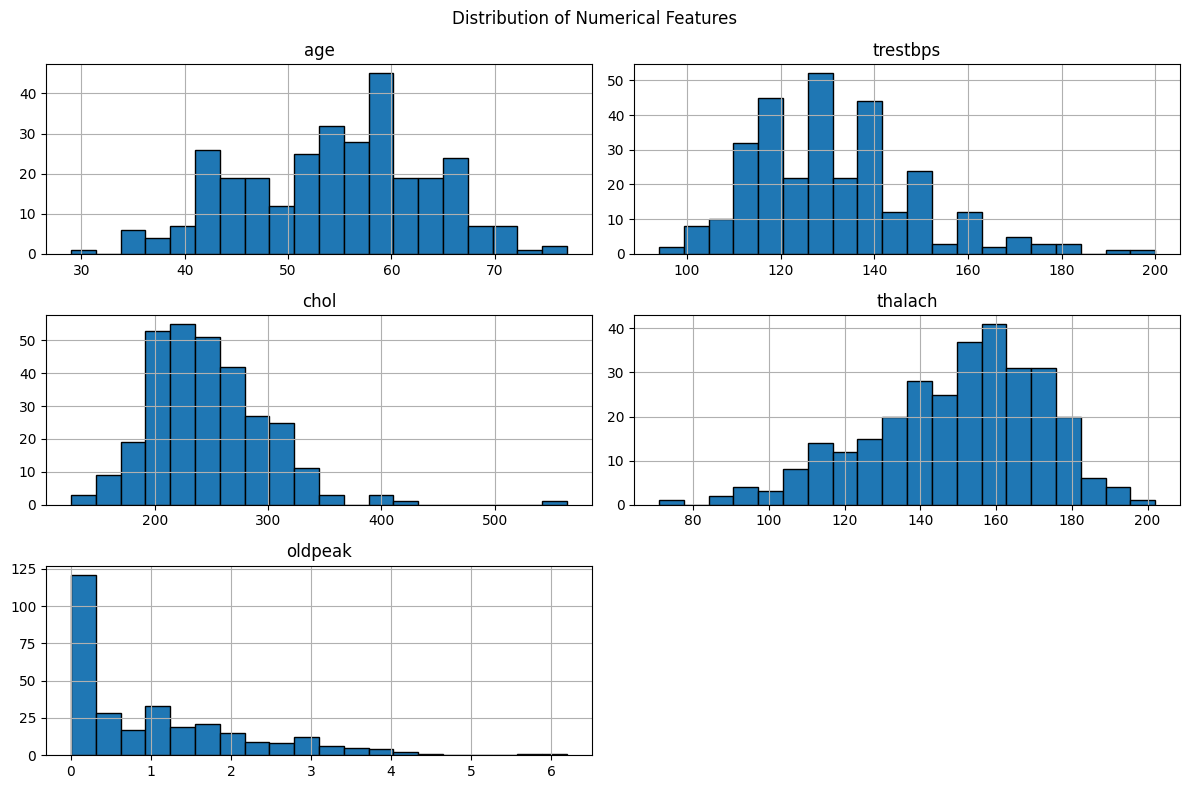

In [8]:
# Histograms for continuous features
df[numerical_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

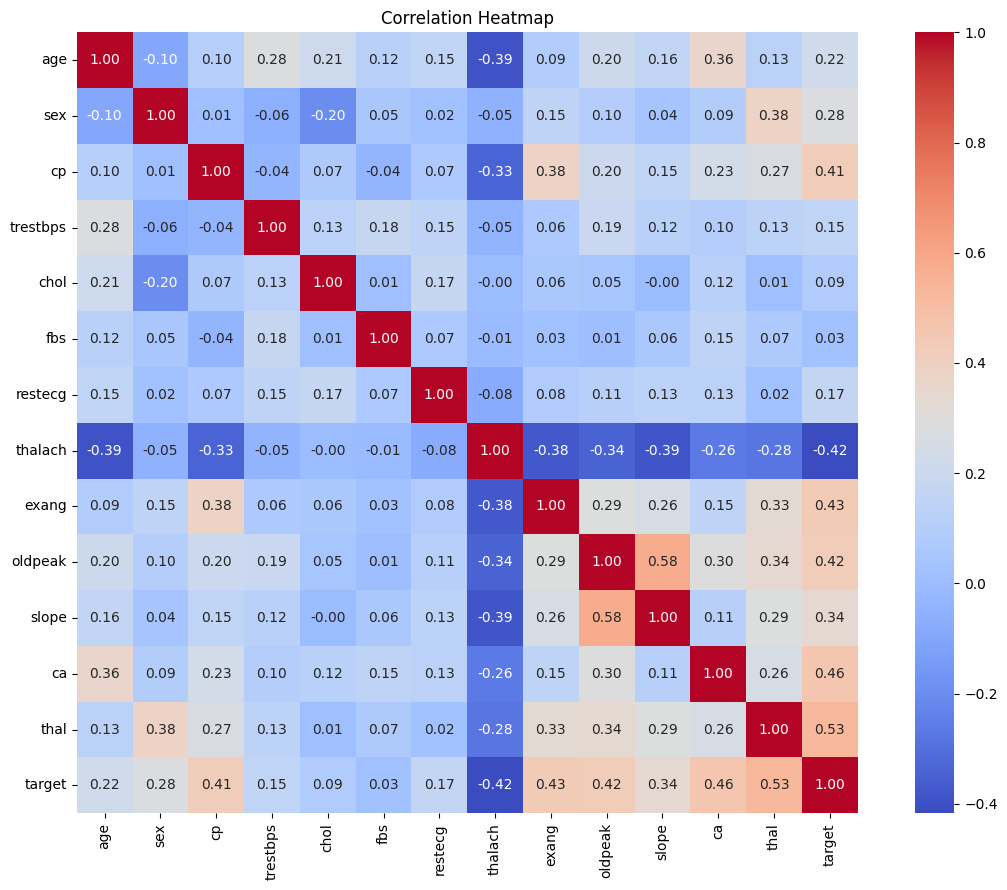

In [9]:
# Correlation heatmap
plt.figure(figsize=(12, 9))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

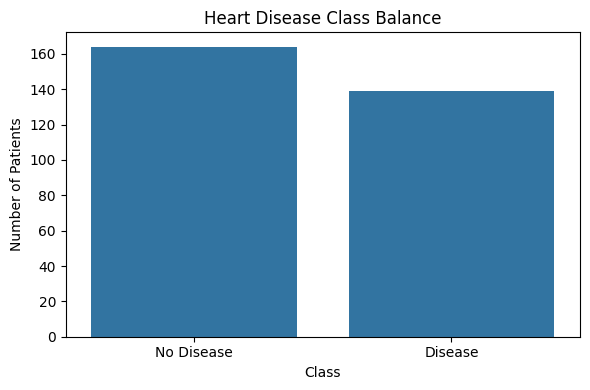

target
0    164
1    139
Name: count, dtype: int64


In [10]:
# Class balance
class_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
sns.barplot(
    x=["No Disease", "Disease"],
    y=class_counts.values
)

plt.title("Heart Disease Class Balance")
plt.xlabel("Class")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

print(class_counts)

In [11]:
# Logistic Regression pipeline
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Random Forest pipeline
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

print("Model pipelines created successfully.")

Model pipelines created successfully.


In [12]:
# Cross-validation settings
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc"
}

# Logistic Regression
logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

# Random Forest
random_forest_cv = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("Logistic Regression CV Results")
print("Accuracy:", logistic_cv["test_accuracy"].mean())
print("Precision:", logistic_cv["test_precision"].mean())
print("Recall:", logistic_cv["test_recall"].mean())
print("ROC-AUC:", logistic_cv["test_roc_auc"].mean())

print("\nRandom Forest CV Results")
print("Accuracy:", random_forest_cv["test_accuracy"].mean())
print("Precision:", random_forest_cv["test_precision"].mean())
print("Recall:", random_forest_cv["test_recall"].mean())
print("ROC-AUC:", random_forest_cv["test_roc_auc"].mean())

Logistic Regression CV Results
Accuracy: 0.8471088435374149
Precision: 0.8767529146045769
Recall: 0.783399209486166
ROC-AUC: 0.9024931590148981

Random Forest CV Results
Accuracy: 0.8139455782312925
Precision: 0.8128787878787879
Recall: 0.773913043478261
ROC-AUC: 0.8926970372622547


In [13]:
# Parameters to test during model tuning
logistic_params = {
    "classifier__C": [0.01, 0.1, 1, 10]
}

random_forest_params = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5]
}

print("Parameter grids created successfully.")

Parameter grids created successfully.


In [14]:
# Tune Logistic Regression
logistic_grid = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=logistic_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

logistic_grid.fit(X_train, y_train)

# Tune Random Forest
random_forest_grid = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=random_forest_params,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

random_forest_grid.fit(X_train, y_train)

print("Logistic Regression best parameters:")
print(logistic_grid.best_params_)
print("Best CV ROC-AUC:", logistic_grid.best_score_)

print("\nRandom Forest best parameters:")
print(random_forest_grid.best_params_)
print("Best CV ROC-AUC:", random_forest_grid.best_score_)

Logistic Regression best parameters:
{'classifier__C': 1}
Best CV ROC-AUC: 0.9024931590148981

Random Forest best parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 300}
Best CV ROC-AUC: 0.899001159870725


In [15]:
# Best models from tuning
best_logistic = logistic_grid.best_estimator_
best_random_forest = random_forest_grid.best_estimator_

# Predictions
logistic_pred = best_logistic.predict(X_test)
logistic_prob = best_logistic.predict_proba(X_test)[:, 1]

random_forest_pred = best_random_forest.predict(X_test)
random_forest_prob = best_random_forest.predict_proba(X_test)[:, 1]

print("Logistic Regression Test Results")
print("Accuracy:", accuracy_score(y_test, logistic_pred))
print("Precision:", precision_score(y_test, logistic_pred))
print("Recall:", recall_score(y_test, logistic_pred))
print("ROC-AUC:", roc_auc_score(y_test, logistic_prob))

print("\nRandom Forest Test Results")
print("Accuracy:", accuracy_score(y_test, random_forest_pred))
print("Precision:", precision_score(y_test, random_forest_pred))
print("Recall:", recall_score(y_test, random_forest_pred))
print("ROC-AUC:", roc_auc_score(y_test, random_forest_prob))

Logistic Regression Test Results
Accuracy: 0.8852459016393442
Precision: 0.8387096774193549
Recall: 0.9285714285714286
ROC-AUC: 0.9664502164502166

Random Forest Test Results
Accuracy: 0.8688524590163934
Precision: 0.8333333333333334
Recall: 0.8928571428571429
ROC-AUC: 0.946969696969697


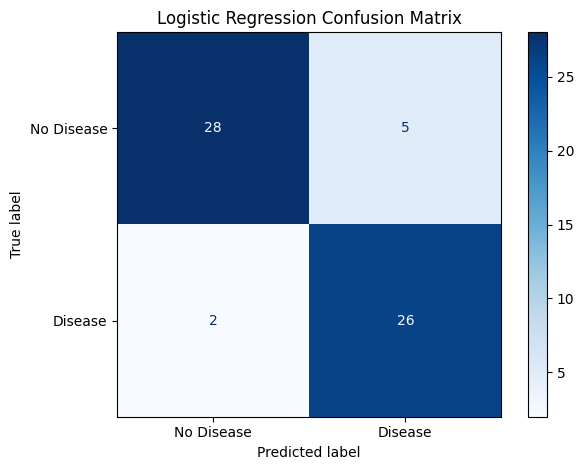

In [16]:
# Confusion matrix for the selected model
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_pred,
    display_labels=["No Disease", "Disease"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

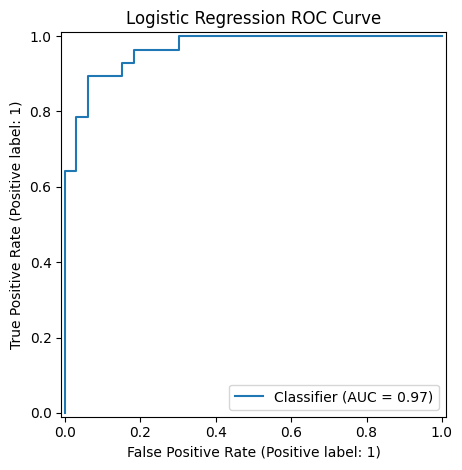

In [17]:
# ROC curve for the selected model
RocCurveDisplay.from_predictions(
    y_test,
    logistic_prob
)

plt.title("Logistic Regression ROC Curve")
plt.tight_layout()
plt.show()

In [18]:
# Select final model
final_model = best_logistic

print("Final model: Logistic Regression")
print("Test accuracy:", accuracy_score(y_test, logistic_pred))
print("Test precision:", precision_score(y_test, logistic_pred))
print("Test recall:", recall_score(y_test, logistic_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, logistic_prob))

Final model: Logistic Regression
Test accuracy: 0.8852459016393442
Test precision: 0.8387096774193549
Test recall: 0.9285714285714286
Test ROC-AUC: 0.9664502164502166


In [19]:
# Set up MLflow experiment
mlflow.set_experiment("heart_disease_experiment")

print("MLflow experiment created successfully.")

2026/10/09 11:52:05 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/09 11:52:05 INFO mlflow.store.db.utils: Updating database tables
2026/10/09 11:52:08 INFO mlflow.tracking.fluent: Experiment with name 'heart_disease_experiment' does not exist. Creating a new experiment.


MLflow experiment created successfully.


In [20]:
# Log Logistic Regression experiment
artifact_dir = Path("mlflow_artifacts")
artifact_dir.mkdir(exist_ok=True)

# Save confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_pred,
    display_labels=["No Disease", "Disease"],
    cmap="Blues",
    ax=ax
)
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
confusion_path = artifact_dir / "logistic_confusion_matrix.png"
plt.savefig(confusion_path)
plt.close()

# Save ROC curve
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test,
    logistic_prob,
    ax=ax
)
plt.title("Logistic Regression ROC Curve")
plt.tight_layout()
roc_path = artifact_dir / "logistic_roc_curve.png"
plt.savefig(roc_path)
plt.close()

with mlflow.start_run(run_name="logistic_regression"):
    mlflow.log_param("model", "Logistic Regression")
    mlflow.log_param("C", logistic_grid.best_params_["classifier__C"])

    mlflow.log_metric("cv_roc_auc", logistic_grid.best_score_)
    mlflow.log_metric("test_accuracy", accuracy_score(y_test, logistic_pred))
    mlflow.log_metric("test_precision", precision_score(y_test, logistic_pred))
    mlflow.log_metric("test_recall", recall_score(y_test, logistic_pred))
    mlflow.log_metric("test_roc_auc", roc_auc_score(y_test, logistic_prob))

    mlflow.log_artifact(str(confusion_path), artifact_path="plots")
    mlflow.log_artifact(str(roc_path), artifact_path="plots")

    mlflow.sklearn.log_model(
        sk_model=best_logistic,
        name="model",
        serialization_format="cloudpickle"
    )

print("Logistic Regression run logged successfully.")

2026/10/09 11:52:09 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logistic Regression run logged successfully.


In [21]:
# Log Random Forest experiment
rf_confusion_path = artifact_dir / "random_forest_confusion_matrix.png"
rf_roc_path = artifact_dir / "random_forest_roc_curve.png"

# Save confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    random_forest_pred,
    display_labels=["No Disease", "Disease"],
    cmap="Blues",
    ax=ax
)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.savefig(rf_confusion_path)
plt.close()

# Save ROC curve
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(
    y_test,
    random_forest_prob,
    ax=ax
)
plt.title("Random Forest ROC Curve")
plt.tight_layout()
plt.savefig(rf_roc_path)
plt.close()

with mlflow.start_run(run_name="random_forest"):
    mlflow.log_param("model", "Random Forest")
    mlflow.log_param(
        "n_estimators",
        random_forest_grid.best_params_["classifier__n_estimators"]
    )
    mlflow.log_param(
        "max_depth",
        random_forest_grid.best_params_["classifier__max_depth"]
    )
    mlflow.log_param(
        "min_samples_split",
        random_forest_grid.best_params_["classifier__min_samples_split"]
    )

    mlflow.log_metric("cv_roc_auc", random_forest_grid.best_score_)
    mlflow.log_metric(
        "test_accuracy",
        accuracy_score(y_test, random_forest_pred)
    )
    mlflow.log_metric(
        "test_precision",
        precision_score(y_test, random_forest_pred)
    )
    mlflow.log_metric(
        "test_recall",
        recall_score(y_test, random_forest_pred)
    )
    mlflow.log_metric(
        "test_roc_auc",
        roc_auc_score(y_test, random_forest_prob)
    )

    mlflow.log_artifact(
        str(rf_confusion_path),
        artifact_path="plots"
    )
    mlflow.log_artifact(
        str(rf_roc_path),
        artifact_path="plots"
    )

    mlflow.sklearn.log_model(
        sk_model=best_random_forest,
        name="model",
        serialization_format="cloudpickle"
    )

print("Random Forest run logged successfully.")

2026/10/09 11:52:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Random Forest run logged successfully.


In [22]:
import subprocess

mlflow_process = subprocess.Popen(
    ["mlflow", "ui", "--host", "0.0.0.0", "--port", "5000"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

print("MLflow UI started.")

MLflow UI started.


In [23]:
# Check logged MLflow runs
experiment = mlflow.get_experiment_by_name("heart_disease_experiment")

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

runs[
    [
        "tags.mlflow.runName",
        "metrics.cv_roc_auc",
        "metrics.test_accuracy",
        "metrics.test_precision",
        "metrics.test_recall",
        "metrics.test_roc_auc"
    ]
]

,tags.mlflow.runName,metrics.cv_roc_auc,metrics.test_accuracy,metrics.test_precision,metrics.test_recall,metrics.test_roc_auc
0,random_forest,0.899001,0.868852,0.833333,0.892857,0.94697
1,logistic_regression,0.902493,0.885246,0.838710,0.928571,0.96645


In [24]:
# Save final model pipeline
model_dir = Path("model")
model_dir.mkdir(exist_ok=True)

model_path = model_dir / "heart_disease_model.joblib"

joblib.dump(final_model, model_path)

print("Model saved to:", model_path)

Model saved to: model/heart_disease_model.joblib


In [25]:
# Reload saved model
loaded_model = joblib.load(model_path)

sample_input = X_test.iloc[[0]]
sample_prediction = loaded_model.predict(sample_input)
sample_probability = loaded_model.predict_proba(sample_input)[:, 1]

print("Loaded model prediction:", sample_prediction[0])
print("Loaded model probability:", sample_probability[0])

Loaded model prediction: 0
Loaded model probability: 0.20929566898365365


In [26]:
# Create requirements file
requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
ucimlrepo
mlflow
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully.")

requirements.txt created successfully.


In [27]:
# Check requirements file
with open("requirements.txt", "r") as file:
    print(file.read())

pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
ucimlrepo
mlflow



In [28]:
# Create project folders
project_folders = [
    "src",
    "tests",
    ".github/workflows",
    "screenshots"
]

for folder in project_folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Project folders created successfully.")

Project folders created successfully.


In [29]:
# Create reusable training script
train_code = '''import joblib
import pandas as pd
from pathlib import Path

from ucimlrepo import fetch_ucirepo
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


CATEGORICAL_FEATURES = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

NUMERICAL_FEATURES = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]


def load_data():
    heart_disease = fetch_ucirepo(id=45)

    features = heart_disease.data.features.copy()
    target = heart_disease.data.targets.copy()

    data = pd.concat([features, target], axis=1)
    data["target"] = (data["num"] > 0).astype(int)
    data = data.drop(columns=["num"])

    return data


def build_pipeline():
    numerical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numerical_transformer, NUMERICAL_FEATURES),
            ("cat", categorical_transformer, CATEGORICAL_FEATURES)
        ]
    )

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            C=1,
            max_iter=1000,
            random_state=42
        ))
    ])

    return model


def train_model():
    data = load_data()

    X = data.drop(columns=["target"])
    y = data["target"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    model = build_pipeline()
    model.fit(X_train, y_train)

    return model, X_test, y_test


if __name__ == "__main__":
    model, _, _ = train_model()

    model_dir = Path("model")
    model_dir.mkdir(exist_ok=True)

    joblib.dump(model, model_dir / "heart_disease_model.joblib")

    print("Training completed successfully.")
'''

Path("src/train.py").write_text(train_code)

print("src/train.py created successfully.")

src/train.py created successfully.


In [30]:
!python src/train.py

Training completed successfully.


In [32]:
# Create unit tests
test_code = '''from src.train import load_data, build_pipeline, train_model


def test_load_data():
    data = load_data()

    assert data.shape[0] > 0
    assert "target" in data.columns
    assert "num" not in data.columns
    assert set(data["target"].unique()).issubset({0, 1})


def test_build_pipeline():
    model = build_pipeline()

    assert "preprocessor" in model.named_steps
    assert "classifier" in model.named_steps


def test_train_model():
    model, X_test, y_test = train_model()

    predictions = model.predict(X_test)

    assert len(predictions) == len(y_test)
    assert set(predictions).issubset({0, 1})
'''

Path("tests/test_train.py").write_text(test_code)

print("tests/test_train.py created successfully.")

tests/test_train.py created successfully.


In [34]:
# Make src importable
Path("src/__init__.py").touch()

print("src package created successfully.")

src package created successfully.


In [37]:
!python -m pytest -q

...                                                                      [100%]
3 passed in 3.20s


In [38]:
# Add pytest to requirements
requirements = """pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
ucimlrepo
mlflow
pytest
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt updated successfully.")

requirements.txt updated successfully.


In [39]:
# Create GitHub Actions workflow
workflow = """name: MLOps CI

on:
  push:
    branches: [ main ]
  pull_request:
    branches: [ main ]

jobs:
  test-and-train:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt
          pip install flake8

      - name: Run linting
        run: |
          flake8 src tests --max-line-length=88

      - name: Run unit tests
        run: |
          python -m pytest -q

      - name: Train model
        run: |
          python src/train.py

      - name: Upload trained model
        uses: actions/upload-artifact@v4
        with:
          name: heart-disease-model
          path: model/heart_disease_model.joblib
"""

Path(".github/workflows/ci.yml").write_text(workflow)

print("GitHub Actions workflow created successfully.")

GitHub Actions workflow created successfully.


In [40]:
!find . -maxdepth 3 -type f | sort

./.config/active_config
./.config/config_sentinel
./.config/configurations/config_default
./.config/default_configs.db
./.config/gce
./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
./.config/.last_opt_in_prompt.yaml
./.config/.last_survey_prompt.yaml
./.config/.last_update_check.json
./.github/workflows/ci.yml
./mlflow_artifacts/logistic_confusion_matrix.png
./mlflow_artifacts/logistic_roc_curve.png
./mlflow_artifacts/random_forest_confusion_matrix.png
./mlflow_artifacts/random_forest_roc_curve.png
./mlflow.db
./model/heart_disease_model.joblib
./.pytest_cache/CACHEDIR.TAG
./.pytest_cache/.gitignore
./.pytest_cache/README.md
./requirements.txt
./sample_data/anscombe.json
./sample_data/california_housing_test.csv
./sample_data/california_housing_train.csv
./sample_data/mnist_test.csv
./sample_data/mnist_train_small.csv
./sample_data/README.md
./src/__init__.py
./src/__pycache__/__init__.cpython-313.pyc
./src/__pycache__/train.cpython-313.pyc
./src/train.py
./tes

In [41]:
# Ignore temporary and generated files
gitignore = """__pycache__/
*.pyc
.pytest_cache/
sample_data/
mlflow.db
mlruns/
"""

Path(".gitignore").write_text(gitignore)

print(".gitignore created successfully.")

.gitignore created successfully.


In [42]:
!pip -q install flake8
!flake8 src tests --max-line-length=88

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 2.5 MB/s eta 0:00:00


In [43]:
print(Path(".github/workflows/ci.yml").read_text())

name: MLOps CI

on:
  push:
    branches: [ main ]
  pull_request:
    branches: [ main ]

jobs:
  test-and-train:
    runs-on: ubuntu-latest

    steps:
      - name: Checkout repository
        uses: actions/checkout@v4

      - name: Set up Python
        uses: actions/setup-python@v5
        with:
          python-version: "3.11"

      - name: Install dependencies
        run: |
          python -m pip install --upgrade pip
          pip install -r requirements.txt
          pip install flake8

      - name: Run linting
        run: |
          flake8 src tests --max-line-length=88

      - name: Run unit tests
        run: |
          python -m pytest -q

      - name: Train model
        run: |
          python src/train.py

      - name: Upload trained model
        uses: actions/upload-artifact@v4
        with:
          name: heart-disease-model
          path: model/heart_disease_model.joblib



In [44]:
!git init
!git branch -M main
!git remote add origin https://github.com/Thejus27/heart-disease-mlops.git
!git remote -v

hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/.git/
origin	https://github.com/Thejus27/heart-disease-mlops.git (fetch)
origin	https://github.com/Thejus27/heart-disease-mlops.git (push)


In [45]:
!git status --short

?? .config/
?? .github/
?? .gitignore
?? mlflow_artifacts/
?? model/
?? requirements.txt
?? src/
?? tests/


In [46]:
# Update ignored files
gitignore = """.config/
__pycache__/
*.pyc
.pytest_cache/
sample_data/
mlflow.db
mlruns/
mlflow_artifacts/
"""

Path(".gitignore").write_text(gitignore)

print(".gitignore updated successfully.")

.gitignore updated successfully.


In [47]:
!git status --short

?? .github/
?? .gitignore
?? model/
?? requirements.txt
?? src/
?? tests/
